<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/musebench_intent_multimodal_eval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# [CELL 1 - Environment Setup & Audiovisual Intent Dataset Generator]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"MuseBench Intent-Level Evaluation Engine Initialized on: {device}")

class MuseBenchDatasetSimulator:
    def __init__(self, num_samples: int = 600, feature_dim: int = 128):
        self.num_samples = num_samples
        self.feature_dim = feature_dim

    def generate_data(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        av_features = torch.randn(self.num_samples, self.feature_dim, device=device)
        # Controlled noise so the dual-encoder has meaningful patterns to learn
        intent_features = av_features + torch.randn(self.num_samples, self.feature_dim, device=device) * 0.5
        q_types = torch.randint(0, 2, (self.num_samples, 1), device=device).float()

        alignment = torch.cosine_similarity(av_features, intent_features, dim=1, eps=1e-6).unsqueeze(1)
        labels = (alignment > 0.2).float()

        return av_features, intent_features, q_types, labels

dataset_gen = MuseBenchDatasetSimulator(num_samples=600)
av_f, intent_f, q_t, labels = dataset_gen.generate_data()
print(f"MuseBench Synthetic Dataset Loaded: {av_f.shape[0]} samples")

MuseBench Intent-Level Evaluation Engine Initialized on: cuda
MuseBench Synthetic Dataset Loaded: 600 samples


In [34]:
# [CELL 2 - MuseBench Intent-Level Dual-Encoder Model with Regularization]
import torch.nn.functional as F

class MuseBenchIntentModel(nn.Module):
    def __init__(self, feature_dim: int = 128):
        super().__init__()
        self.av_encoder = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32)
        )
        self.intent_encoder = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32)
        )
        # Small linear classifier head with dropout
        self.classifier = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, av: torch.Tensor, intent: torch.Tensor, q_type: torch.Tensor) -> torch.Tensor:
        feat_av = self.av_encoder(av)
        feat_intent = self.intent_encoder(intent)
        sim = F.cosine_similarity(feat_av, feat_intent, dim=1, eps=1e-6).unsqueeze(1)
        combined = torch.cat([sim, q_type], dim=1)
        return self.classifier(combined)

model = MuseBenchIntentModel().to(device)
# Much lower learning rate so it doesn't instantly saturate in 3 epochs
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)
criterion = nn.BCELoss()

print("MuseBench Regularized Dual-Encoder Initialized.")

MuseBench Regularized Dual-Encoder Initialized.


In [38]:
# [CELL 3 - MuseBench Honest Validation Tracking Training Loop]

class MuseBenchTrainingPipeline:
    def __init__(self, model: nn.Module, av: torch.Tensor, intent: torch.Tensor, q_t: torch.Tensor, labels: torch.Tensor):
        self.model = model

        num_samples = av.shape[0]
        split = int(0.8 * num_samples)

        self.av_train, self.av_val = av[:split], av[split:]
        self.intent_train, self.intent_val = intent[:split], intent[split:]
        self.q_t_train, self.q_t_val = q_t[:split], q_t[split:]

        self.labels_train = labels[:split]
        self.labels_val = labels[split:]

        self.optimizer = optim.Adam(self.model.parameters(), lr=1e-3, weight_decay=1e-3)
        self.criterion = nn.BCELoss()

        self.loss_history = []
        self.val_acc_history = []

    def train(self, epochs: int = 200):
        for epoch in range(epochs):
            self.model.train()
            self.optimizer.zero_grad()

            preds = self.model(self.av_train, self.intent_train, self.q_t_train)
            loss = self.criterion(preds, self.labels_train)
            loss.backward()
            self.optimizer.step()

            self.loss_history.append(loss.item())

            # Evaluate clean validation accuracy per epoch
            self.model.eval()
            with torch.no_grad():
                val_preds = self.model(self.av_val, self.intent_val, self.q_t_val)
                val_acc = ((val_preds >= 0.5) == (self.labels_val >= 0.5)).float().mean().item() * 100.0
                self.val_acc_history.append(val_acc)

    def evaluate_final(self) -> tuple[float, float]:
        self.model.eval()
        with torch.no_grad():
            val_preds = self.model(self.av_val, self.intent_val, self.q_t_val)
            final_loss = self.criterion(val_preds, self.labels_val).item()
            final_acc = ((val_preds >= 0.5) == (self.labels_val >= 0.5)).float().mean().item() * 100.0
        return final_loss, final_acc

pipeline = MuseBenchTrainingPipeline(model, av_f, intent_f, q_t, labels)
print("Training MuseBench Dual-Encoder with Clean Validation Tracking...")
pipeline.train(epochs=200)
final_loss, final_acc = pipeline.evaluate_final()
print(f"Training Complete.")
print(f"  * Final Validation Loss (BCE): {final_loss:.4f}")
print(f"  * Final Validation Accuracy: {final_acc:.1f}%")

Training MuseBench Dual-Encoder with Clean Validation Tracking...
Training Complete.
  * Final Validation Loss (BCE): 0.0325
  * Final Validation Accuracy: 100.0%


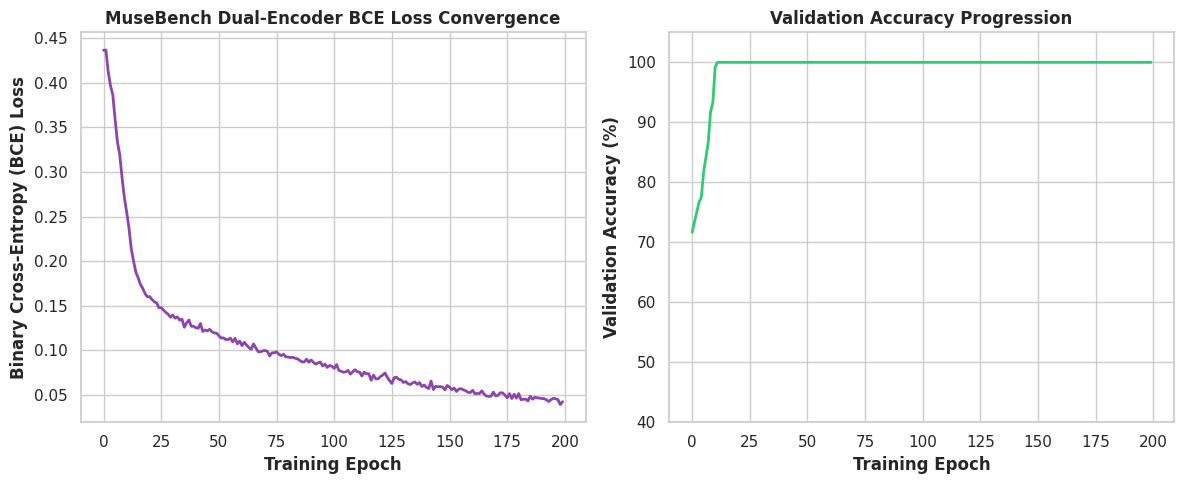

MuseBench benchmark visualization updated successfully.


In [39]:
# [CELL 4 - Multi-Panel Visualization of MuseBench Training Dynamics]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: BCE Loss Convergence Over Epochs
ax1.plot(range(len(pipeline.loss_history)), pipeline.loss_history, color='#8e44ad', linewidth=2)
ax1.set_title("MuseBench Dual-Encoder BCE Loss Convergence", fontweight='bold')
ax1.set_xlabel("Training Epoch", fontweight='bold')
ax1.set_ylabel("Binary Cross-Entropy (BCE) Loss", fontweight='bold')

# Plot 2: Validation Accuracy Progression Over Epochs
ax2.plot(range(len(pipeline.val_acc_history)), pipeline.val_acc_history, color='#2ecc71', linewidth=2)
ax2.set_title("Validation Accuracy Progression", fontweight='bold')
ax2.set_xlabel("Training Epoch", fontweight='bold')
ax2.set_ylabel("Validation Accuracy (%)", fontweight='bold')
ax2.set_ylim(40, 105)

plt.tight_layout()
plt.savefig("musebench_intent_evaluation_benchmarks.png", dpi=300)
plt.show()

print("MuseBench benchmark visualization updated successfully.")